In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df_co_ft = pd.read_csv("Dataset/Data/Colorado/acsincome_co_allfeatures.csv")
df_co_lbl = pd.read_csv("Dataset/Data/Colorado/acsincome_co_label.csv")

In [3]:
df_ca_ft = pd.read_csv("Dataset/Data/California/acsincome_ca_features.csv")
df_ca_lbl = pd.read_csv("Dataset/Data/California/acsincome_ca_labels.csv")

In [4]:
df_ne_ft = pd.read_csv("Dataset/Data/Nebraska/acsincome_ne_allfeatures.csv")
df_ne_lbl = pd.read_csv("Dataset/Data/Nebraska/acsincome_ne_label.csv")

In [5]:
df_co_ft.head(5)

,AGEP,COW,SCHL,MAR,OCCP,POBP,RELP,WKHP,SEX,RAC1P
0,19.0,2.0,19.0,5.0,2850.0,6.0,17.0,2.0,2.0,9.0
1,24.0,5.0,18.0,5.0,9645.0,13.0,17.0,40.0,1.0,2.0
2,22.0,1.0,19.0,5.0,1520.0,53.0,17.0,45.0,2.0,1.0
3,32.0,1.0,16.0,1.0,4055.0,8.0,16.0,40.0,2.0,1.0
4,19.0,2.0,19.0,5.0,2006.0,34.0,17.0,9.0,2.0,1.0


In [6]:
df_ca_ft.head(5)

,AGEP,COW,SCHL,MAR,OCCP,POBP,RELP,WKHP,SEX,RAC1P
0,41.0,4.0,24.0,1.0,2555.0,6.0,1.0,60.0,2.0,1.0
1,77.0,7.0,22.0,1.0,4920.0,39.0,0.0,35.0,1.0,1.0
2,38.0,1.0,18.0,1.0,440.0,6.0,1.0,50.0,1.0,1.0
3,30.0,1.0,22.0,5.0,1555.0,6.0,2.0,80.0,1.0,6.0
4,36.0,1.0,16.0,1.0,4030.0,314.0,1.0,70.0,2.0,1.0


In [7]:
df_ne_ft.head(5)

,AGEP,COW,SCHL,MAR,OCCP,POBP,RELP,WKHP,SEX,RAC1P
0,19.0,1.0,19.0,5.0,3960.0,31.0,17.0,20.0,2.0,1.0
1,22.0,4.0,19.0,5.0,4622.0,46.0,17.0,30.0,1.0,1.0
2,19.0,1.0,19.0,5.0,6260.0,31.0,17.0,40.0,1.0,1.0
3,50.0,1.0,20.0,4.0,9620.0,31.0,17.0,10.0,1.0,1.0
4,18.0,1.0,18.0,5.0,3960.0,31.0,17.0,20.0,1.0,1.0


<h1> Problématique : Analyse : Quels sont les éléments les plus correlés au revenu des individus ? </h1>

<h2>Existence de biais ? Ex : changement des biais entre les états ?</h2>

<h2>Étape 1 : regarder données manquantes </h2>

In [8]:
ft = df_co_ft.columns
print(ft)
i = 0

Index(['AGEP', 'COW', 'SCHL', 'MAR', 'OCCP', 'POBP', 'RELP', 'WKHP', 'SEX',
       'RAC1P'],
      dtype='object')


In [9]:
i = 0

In [10]:
feature = 'AGEP'

In [11]:
df_co_ft.query(f"{ft[i]} > 100")

,AGEP,COW,SCHL,MAR,OCCP,POBP,RELP,WKHP,SEX,RAC1P


In [12]:
len(df_co_ft.values)

31306

In [13]:
df_co_ft.values[ft.to_list().index(feature)].min()
df_co_ft.query("AGEP == 2")


,AGEP,COW,SCHL,MAR,OCCP,POBP,RELP,WKHP,SEX,RAC1P


In [14]:
lst_age = [df_ca_ft.values[x][ft.to_list().index(feature)] for x in range(31306)]
min(lst_age)

np.float64(17.0)

In [15]:
df_ne_ft.values[ft.to_list().index(feature)].min()

np.float64(1.0)

<h2> On décide de faire un seul dataset contenant les données des 3 états. On ajoute une feature indiquant l'état. </h2>

In [16]:
'''Ajout de l'état'''
df_co_ft['STATE'] = [0 for i in range(len(df_co_ft))]
df_ca_ft['STATE'] = [1 for i in range(len(df_ca_ft))]
df_ne_ft['STATE'] = [2 for i in range(len(df_ne_ft))]

In [17]:
'''Création du dataset global'''
df_tot_ft = pd.concat([df_co_ft, df_ca_ft, df_ne_ft])

In [18]:
len(df_tot_ft)

208406

In [19]:
df_tot_ft.head()

,AGEP,COW,SCHL,MAR,OCCP,POBP,RELP,WKHP,SEX,RAC1P,STATE
0,19.0,2.0,19.0,5.0,2850.0,6.0,17.0,2.0,2.0,9.0,0
1,24.0,5.0,18.0,5.0,9645.0,13.0,17.0,40.0,1.0,2.0,0
2,22.0,1.0,19.0,5.0,1520.0,53.0,17.0,45.0,2.0,1.0,0
3,32.0,1.0,16.0,1.0,4055.0,8.0,16.0,40.0,2.0,1.0,0
4,19.0,2.0,19.0,5.0,2006.0,34.0,17.0,9.0,2.0,1.0,0


In [20]:
df_tot_ft.describe()

,AGEP,COW,SCHL,MAR,OCCP,POBP,RELP,WKHP,SEX,RAC1P,STATE
count,208406.000000,208406.000000,208406.000000,208406.000000,208406.000000,208406.000000,208406.000000,208406.000000,208406.000000,208406.000000,208406.000000
mean,42.802702,2.158978,18.580972,2.613696,4009.454517,84.338853,2.452228,38.070646,1.471757,2.764191,0.901534
std,14.974851,1.899134,3.774770,1.834904,2643.232249,117.026582,4.448480,13.123341,0.499203,2.794662,0.438488
min,17.000000,1.000000,1.000000,1.000000,10.000000,1.000000,0.000000,1.000000,1.000000,1.000000,0.000000
25%,30.000000,1.000000,16.000000,1.000000,2014.000000,6.000000,0.000000,32.000000,1.000000,1.000000,1.000000
50%,42.000000,1.000000,19.000000,1.000000,4055.000000,17.000000,1.000000,40.000000,1.000000,1.000000,1.000000
75%,55.000000,3.000000,21.000000,5.000000,5522.000000,206.000000,2.000000,40.000000,2.000000,6.000000,1.000000
max,95.000000,8.000000,24.000000,5.000000,9830.000000,554.000000,17.000000,99.000000,2.000000,9.000000,2.000000


<h2> Analyse univariée</h2>

<h3> Données numériques </h3>

<h4>AGE</h4>

Text(0.5, 1.0, "Plot violon de l'âge")

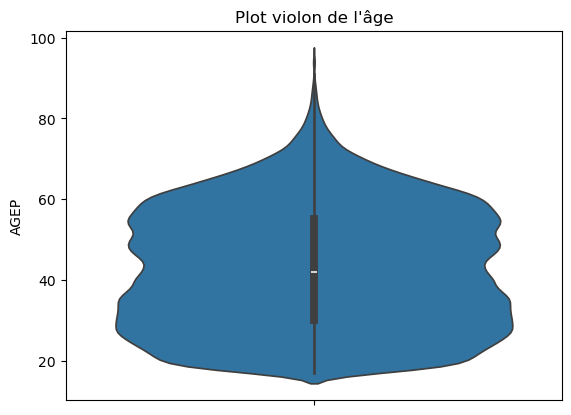

In [21]:
sns.violinplot(df_tot_ft, y = "AGEP")
plt.title("Plot violon de l'âge")

<h4> WKHP </h4>

Text(0.5, 1.0, "Plot violon du nombre d'heures de travail hebdomadaires")

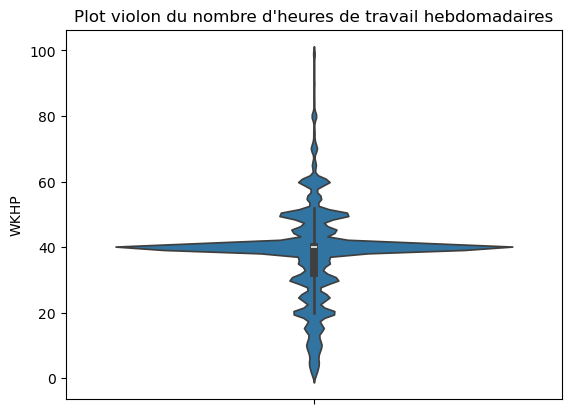

In [22]:
sns.violinplot(df_tot_ft, y = "WKHP")
plt.title("Plot violon du nombre d'heures de travail hebdomadaires")

In [23]:
print(len(df_tot_ft.query("WKHP >= 99")))
df_tot_ft.query("WKHP >= 99")

338


,AGEP,COW,SCHL,MAR,OCCP,POBP,RELP,WKHP,SEX,RAC1P,STATE
1400,30.0,1.0,19.0,1.0,7140.0,36.0,0.0,99.0,1.0,1.0,0
2687,49.0,1.0,13.0,1.0,6305.0,8.0,0.0,99.0,1.0,1.0,0
2696,76.0,2.0,21.0,1.0,3740.0,6.0,0.0,99.0,1.0,1.0,0
3020,23.0,1.0,18.0,5.0,6850.0,8.0,12.0,99.0,1.0,1.0,0
3977,31.0,1.0,16.0,5.0,6200.0,8.0,0.0,99.0,1.0,1.0,0
...,...,...,...,...,...,...,...,...,...,...,...
8987,26.0,2.0,19.0,1.0,4600.0,34.0,0.0,99.0,2.0,9.0,2
8988,29.0,2.0,20.0,1.0,3602.0,26.0,1.0,99.0,1.0,1.0,2
9055,35.0,6.0,21.0,1.0,9130.0,20.0,0.0,99.0,1.0,1.0,2
9711,47.0,6.0,20.0,5.0,205.0,31.0,0.0,99.0,1.0,1.0,2


<h3> Valeurs catégoriques</h3>

array([[<Axes: title={'center': 'COW'}>]], dtype=object)

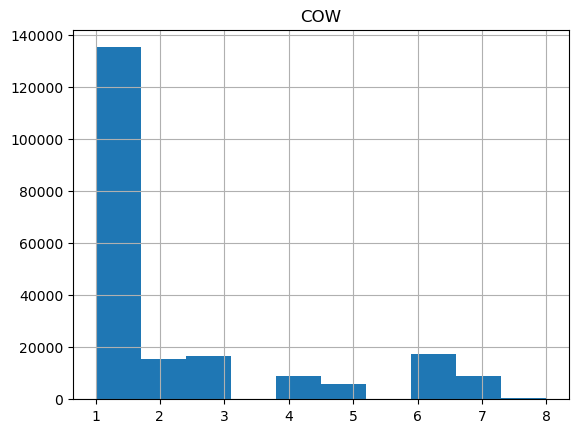

In [24]:
df_tot_ft.hist('COW')

array([[<Axes: title={'center': 'OCCP'}>]], dtype=object)

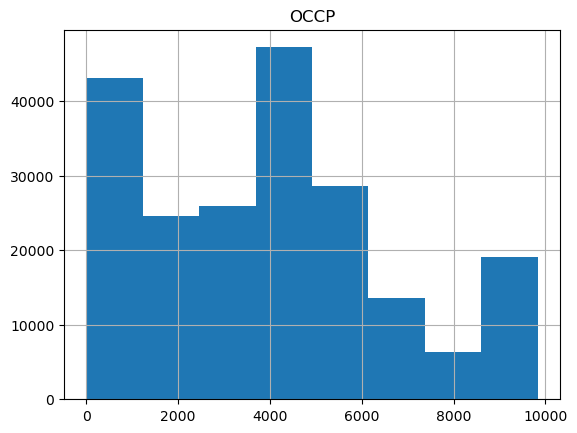

In [26]:
df_tot_ft.hist('OCCP', bins = 8)

In [54]:
df_tot_ft.query("9800 > OCCP > 9760")

,AGEP,COW,SCHL,MAR,OCCP,POBP,RELP,WKHP,SEX,RAC1P,STATE


In [27]:
census_occupation_subcategories_2018 = {
    # Sous-catégories de "Management, Business, Science, and Arts Occupations" (0010-3550)
    "Management, Business, and Financial Occupations": [10, 960],  #[cite: 81]
    "Computer, Engineering, and Science Occupations": [1005, 1980],  #[cite: 82]
    "Education, Legal, Community Service, Arts, and Media Occupations": [2001, 2970],  #[cite: 84]
    "Healthcare Practitioners and Technical Occupations": [3000, 3550],  #[cite: 86]
   
    # Sous-catégories de "Service Occupations" (3601-4655)
    "Healthcare Support Occupations": [3601, 3655],  #[cite: 87]
    "Protective Service Occupations": [3700, 3960],  #[cite: 87]
    "Food Preparation and Serving Related Occupations": [4000, 4160],  #[cite: 88]
    "Building and Grounds Cleaning and Maintenance Occupations": [4200, 4255],  #[cite: 88]
    "Personal Care and Service Occupations": [4330, 4655],  #[cite: 88]
   
    # Sous-catégories de "Sales and Office Occupations" (4700-5940)
    "Sales and Related Occupations": [4700, 4965],  #[cite: 89]
    "Office and Administrative Support Occupations": [5000, 5940],  #[cite: 89]
   
    # Sous-catégories de "Natural Resources, Construction, and Maintenance Occupations" (6005-7640)
    "Farming, Fishing, and Forestry Occupations": [6005, 6130],  #[cite: 90]
    "Construction and Extraction Occupations": [6200, 6950],  #[cite: 91]
    "Installation, Maintenance, and Repair Occupations": [7000, 7640],  #[cite: 92]
   
    # Sous-catégories de "Production, Transportation, and Material Moving Occupations" (7700-9760)
    "Production Occupations": [7700, 8990],  #[cite: 93]
    "Transportation and Material Moving Occupations": [9005, 9760],  #[cite: 94]
   
    # Catégorie militaire
    "Military Specific Occupations": [9800, 9830],  #[cite: 95]
}

In [35]:
dico = {
    # Sous-catégories de "Management, Business, Science, and Arts Occupations" (0010-3550)
    "Management, Business, and Financial Occupations": 0,  #[cite: 81]
    "Computer, Engineering, and Science Occupations": 1,  #[cite: 82]
    "Education, Legal, Community Service, Arts, and Media Occupations": 2,  #[cite: 84]
    "Healthcare Practitioners and Technical Occupations": 3,  #[cite: 86]
   
    # Sous-catégories de "Service Occupations" (3601-4655)
    "Healthcare Support Occupations": 4,  #[cite: 87]
    "Protective Service Occupations": 5,  #[cite: 87]
    "Food Preparation and Serving Related Occupations": 6,  #[cite: 88]
    "Building and Grounds Cleaning and Maintenance Occupations": 7,  #[cite: 88]
    "Personal Care and Service Occupations": 8,  #[cite: 88]
   
    # Sous-catégories de "Sales and Office Occupations" (4700-5940)
    "Sales and Related Occupations": 9,  #[cite: 89]
    "Office and Administrative Support Occupations": 10,  #[cite: 89]
   
    # Sous-catégories de "Natural Resources, Construction, and Maintenance Occupations" (6005-7640)
    "Farming, Fishing, and Forestry Occupations": 11,  #[cite: 90]
    "Construction and Extraction Occupations": 12,  #[cite: 91]
    "Installation, Maintenance, and Repair Occupations": 13,  #[cite: 92]
   
    # Sous-catégories de "Production, Transportation, and Material Moving Occupations" (7700-9760)
    "Production Occupations": 14,  #[cite: 93]
    "Transportation and Material Moving Occupations": 15,  #[cite: 94]
   
    # Catégorie militaire
    "Military Specific Occupations": 16,  #[cite: 95]
}

In [59]:
lst = []
for x in range(len(df_tot_ft)) :
    v = df_tot_ft.values[x][ft.to_list().index('OCCP')]
    for k in census_occupation_subcategories_2018.keys() :
        if v in range(census_occupation_subcategories_2018[k][0], census_occupation_subcategories_2018[k][1] +1) :
            lst.append(dico[k])

df_tot_ft["OCCP_CAT"] = lst

KeyboardInterrupt: 

In [58]:
print([i for i in range(4,20)])

[4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]
